# Recomendación de Cultivos — Baseline con Random Forest y Gradient Boosting

## Propósito
Construir un pipeline reproducible de clasificación multiclase sobre el Crop Recommendation
Dataset (2,200 instancias, 7 variables numéricas) para predecir el cultivo óptimo (`label`) a
partir de condiciones de suelo y clima. Este baseline servirá como referencia para comparar
contra TabPFN (Hollmann et al., 2023).

## Dataset
- **Crop Recommendation Dataset** (Kaggle)
- 2,200 muestras, 22 cultivos, 100 muestras por cultivo (balance perfecto)
- 7 features numéricas: N, P, K, temperature, humidity, ph, rainfall
- Fuente: https://www.kaggle.com/datasets/atharvaingle/crop-recommendation-dataset

## Referencia
Hollmann, N., Müller, S., Purucker, L. et al. (2023).
_Accurate predictions on small data with a tabular foundation model._ Nature.
https://doi.org/10.1038/s41586-024-08328-6


In [2]:
# Imports
import os, sys, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    roc_auc_score, roc_curve,
    classification_report, confusion_matrix
)


In [3]:
# Configuración global
RANDOM_STATE = 42
TEST_SIZE = 0.2
CV_FOLDS = 5
TARGET = 'label'
DATA_PATH = '/content/drive/MyDrive/ML/Crop_recommendation.csv'

sns.set_theme(style='whitegrid', palette='Set2')

## Carga de Datos
Montamos Google Drive y cargamos el dataset. Si no existe, se indica cómo descargarlo.


In [4]:
from google.colab import drive
drive.mount('/content/drive')

# Verificar existencia y cargar
if not os.path.exists(DATA_PATH):
    print(f'Dataset no encontrado en {DATA_PATH}')
    print('Descargar manualmente de Kaggle: atharvaingle/crop-recommendation-dataset')
    raise FileNotFoundError(f'Falta el archivo: {DATA_PATH}')

df = pd.read_csv(DATA_PATH)
print(f'Dimensiones: {df.shape}')
print(f'Columnas: {df.columns.tolist()}')
df.head()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dimensiones: (2200, 8)
Columnas: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


## Análisis Exploratorio de Datos
Verificamos balance de clases, distribuciones, correlaciones y separabilidad.


In [5]:
# 22 clases, 100 muestras cada una — balance perfecto
balance = df[TARGET].value_counts()
print(f'Clases únicas: {len(balance)}')
print(f'Muestras por clase: {balance.unique()}')
print(f'Balance perfecto: {len(balance.unique()) == 1}')

print(f'\nDistribución:')
for k, v in balance.items():
    print(f'  {k:12s}: {v}')


Clases únicas: 22
Muestras por clase: [100]
Balance perfecto: True

Distribución:
  rice        : 100
  maize       : 100
  chickpea    : 100
  kidneybeans : 100
  pigeonpeas  : 100
  mothbeans   : 100
  mungbean    : 100
  blackgram   : 100
  lentil      : 100
  pomegranate : 100
  banana      : 100
  mango       : 100
  grapes      : 100
  watermelon  : 100
  muskmelon   : 100
  apple       : 100
  orange      : 100
  papaya      : 100
  coconut     : 100
  cotton      : 100
  jute        : 100
  coffee      : 100


In [6]:
num_cols = [c for c in df.columns if c != TARGET]

print('Estadísticas descriptivas:')
print(df[num_cols].describe().T.round(2))

nulls = df.isnull().sum()
print(f'\nValores nulos: {nulls.sum()}')
print(f'Duplicados: {df.duplicated().sum()}')


Estadísticas descriptivas:
              count    mean    std    min    25%    50%     75%     max
N            2200.0   50.55  36.92   0.00  21.00  37.00   84.25  140.00
P            2200.0   53.36  32.99   5.00  28.00  51.00   68.00  145.00
K            2200.0   48.15  50.65   5.00  20.00  32.00   49.00  205.00
temperature  2200.0   25.62   5.06   8.83  22.77  25.60   28.56   43.68
humidity     2200.0   71.48  22.26  14.26  60.26  80.47   89.95   99.98
ph           2200.0    6.47   0.77   3.50   5.97   6.43    6.92    9.94
rainfall     2200.0  103.46  54.96  20.21  64.55  94.87  124.27  298.56

Valores nulos: 0
Duplicados: 0


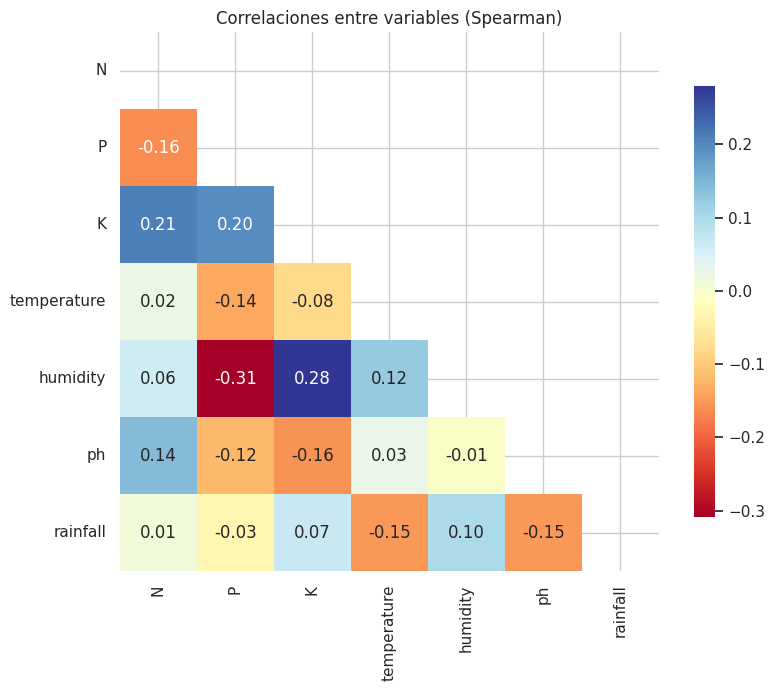

In [7]:
# Correlaciones de Spearman entre variables químicas y climáticas
fig, ax = plt.subplots(figsize=(9, 7))
corr = df[num_cols].corr(method='spearman')
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdYlBu',
            square=True, cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title('Correlaciones entre variables (Spearman)')
plt.show()


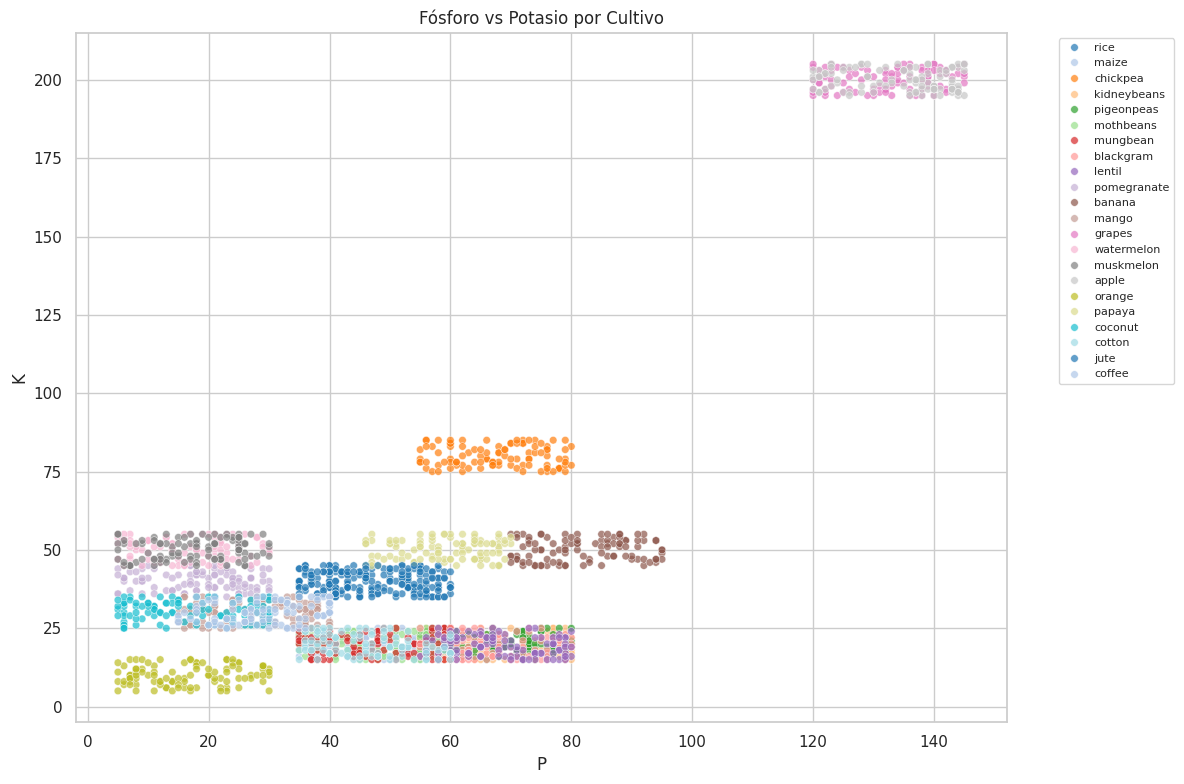

In [8]:
# Dispersión P vs K coloreado por cultivo — muestra agrupaciones naturales
fig, ax = plt.subplots(figsize=(12, 8))
sns.scatterplot(data=df, x='P', y='K', hue=TARGET,
                palette='tab20', s=30, alpha=0.7, ax=ax)
ax.set_title('Fósforo vs Potasio por Cultivo')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()


### Hallazgos
- **Balance perfecto**: 22 clases × 100 muestras. No hay desbalance.
- **Features numéricas todas**: no requiere codificación categórica.
- **Correlaciones**: temperature y humidity correlacionadas; N y P también.
- **Separabilidad**: en el scatter P vs K se ven agrupaciones naturales,
  lo que sugiere que estos predictores discriminan bien entre cultivos.
- **Dataset limpio**: sin nulos, sin duplicados.


## Preprocesamiento
StandardScaler para homogeneizar magnitudes (mm de lluvia vs escala de pH).
No hay nulos ni categóricas que imputar.


In [9]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

# StandardScaler: magnitudes heterogéneas (N en 0-140, rainfall en 20-300)
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
    ],
    verbose_feature_names_out=False
)

print(f'Features ({len(num_cols)}): {num_cols}')
print(f'Clases ({len(y.unique())}): {sorted(y.unique())}')


Features (7): ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
Clases (22): ['apple', 'banana', 'blackgram', 'chickpea', 'coconut', 'coffee', 'cotton', 'grapes', 'jute', 'kidneybeans', 'lentil', 'maize', 'mango', 'mothbeans', 'mungbean', 'muskmelon', 'orange', 'papaya', 'pigeonpeas', 'pomegranate', 'rice', 'watermelon']


In [10]:
# Split estratificado 80/20, semilla fija para reproducibilidad
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
print(f'Train: {X_train.shape[0]} ({X_train.shape[0]/len(X)*100:.0f}%)')
print(f'Test:  {X_test.shape[0]} ({X_test.shape[0]/len(X)*100:.0f}%)')

# Exportar test set para TabPFN
test_out = X_test.copy()
test_out[TARGET] = y_test.values
test_out.to_csv('/content/drive/MyDrive/ML/crop_test.csv', index=False)
print(f'\nTest set exportado: crop_test.csv')


Train: 1760 (80%)
Test:  440 (20%)

Test set exportado: crop_test.csv


## Modelado
Dos pipelines (preprocesador + clasificador) con RandomizedSearchCV.
El foco está en regularizar para evitar sobreajuste: `max_depth` limitado
y `learning_rate` bajo para Gradient Boosting.


In [11]:
# Pipeline con Random Forest
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=RANDOM_STATE))
])

# Grid enfocado en control de sobreajuste
rf_params = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [5, 10, None],
    'classifier__min_samples_split': [2, 5],
}

rf_search = RandomizedSearchCV(
    rf_pipeline, rf_params, n_iter=15, cv=CV_FOLDS,
    scoring='roc_auc_ovr', random_state=RANDOM_STATE, n_jobs=-1, verbose=0
)
rf_search.fit(X_train, y_train)

print('Random Forest')
print(f'  Mejores params: {rf_search.best_params_}')
print(f'  AUC macro (CV): {rf_search.best_score_:.4f}')


Random Forest
  Mejores params: {'classifier__n_estimators': 300, 'classifier__min_samples_split': 5, 'classifier__max_depth': None}
  AUC macro (CV): 1.0000


In [12]:
# Pipeline con Gradient Boosting
gb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(random_state=RANDOM_STATE))
])

# Grid con learning_rate para regularización más fina
gb_params = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [3, 5, 7],
    'classifier__min_samples_split': [2, 5],
    'classifier__learning_rate': [0.05, 0.1, 0.2],
}

gb_search = RandomizedSearchCV(
    gb_pipeline, gb_params, n_iter=20, cv=CV_FOLDS,
    scoring='roc_auc_ovr', random_state=RANDOM_STATE, n_jobs=-1, verbose=0
)
gb_search.fit(X_train, y_train)

print('Gradient Boosting')
print(f'  Mejores params: {gb_search.best_params_}')
print(f'  AUC macro (CV): {gb_search.best_score_:.4f}')


Gradient Boosting
  Mejores params: {'classifier__n_estimators': 100, 'classifier__min_samples_split': 5, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.05}
  AUC macro (CV): 0.9999


Modelo                    AUC CV     AUC Test  
-----------------------------------------------
Random Forest             1.0000     1.0000
Gradient Boosting         0.9999     1.0000

Modelo seleccionado: Random Forest


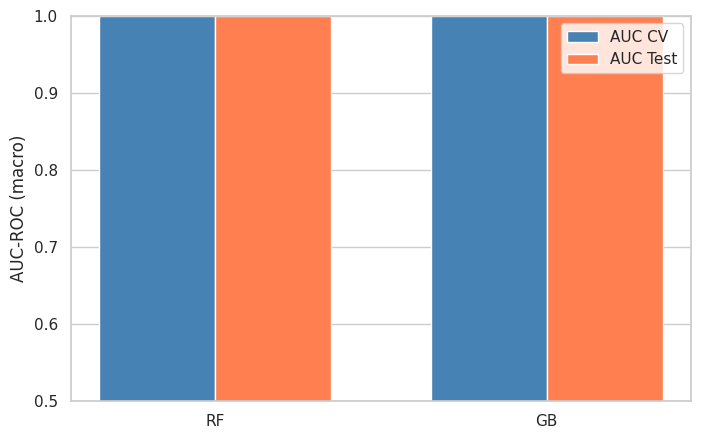

In [13]:
# AUC macro sobre test set (one-vs-rest)
rf_probs = rf_search.predict_proba(X_test)
gb_probs = gb_search.predict_proba(X_test)

rf_auc = roc_auc_score(y_test, rf_probs, multi_class='ovr', average='macro')
gb_auc = roc_auc_score(y_test, gb_probs, multi_class='ovr', average='macro')

print(f'{"Modelo":25s} {"AUC CV":10s} {"AUC Test":10s}')
print('-' * 47)
print(f'{"Random Forest":25s} {rf_search.best_score_:.4f}     {rf_auc:.4f}')
print(f'{"Gradient Boosting":25s} {gb_search.best_score_:.4f}     {gb_auc:.4f}')

best_model = rf_search if rf_auc >= gb_auc else gb_search
best_name = 'Random Forest' if rf_auc >= gb_auc else 'Gradient Boosting'
best_probs = rf_probs if rf_auc >= gb_auc else gb_probs
print(f'\nModelo seleccionado: {best_name}')

fig, ax = plt.subplots(figsize=(8, 5))
w = 0.35; x = range(2)
ax.bar([i - w/2 for i in x], [rf_search.best_score_, gb_search.best_score_], w, label='AUC CV', color='steelblue')
ax.bar([i + w/2 for i in x], [rf_auc, gb_auc], w, label='AUC Test', color='coral')
ax.set_xticks(x); ax.set_xticklabels(['RF', 'GB'])
ax.set_ylabel('AUC-ROC (macro)'); ax.set_ylim(0.5, 1.0); ax.legend()
plt.show()


## Evaluación
Reporte de clasificación, matriz de confusión y curva ROC por clase.


In [14]:
# Predicciones discretas del mejor modelo
y_pred = best_model.predict(X_test)

# Precisión, recall, f1 para las 22 clases
print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        20
      papaya       1.00    

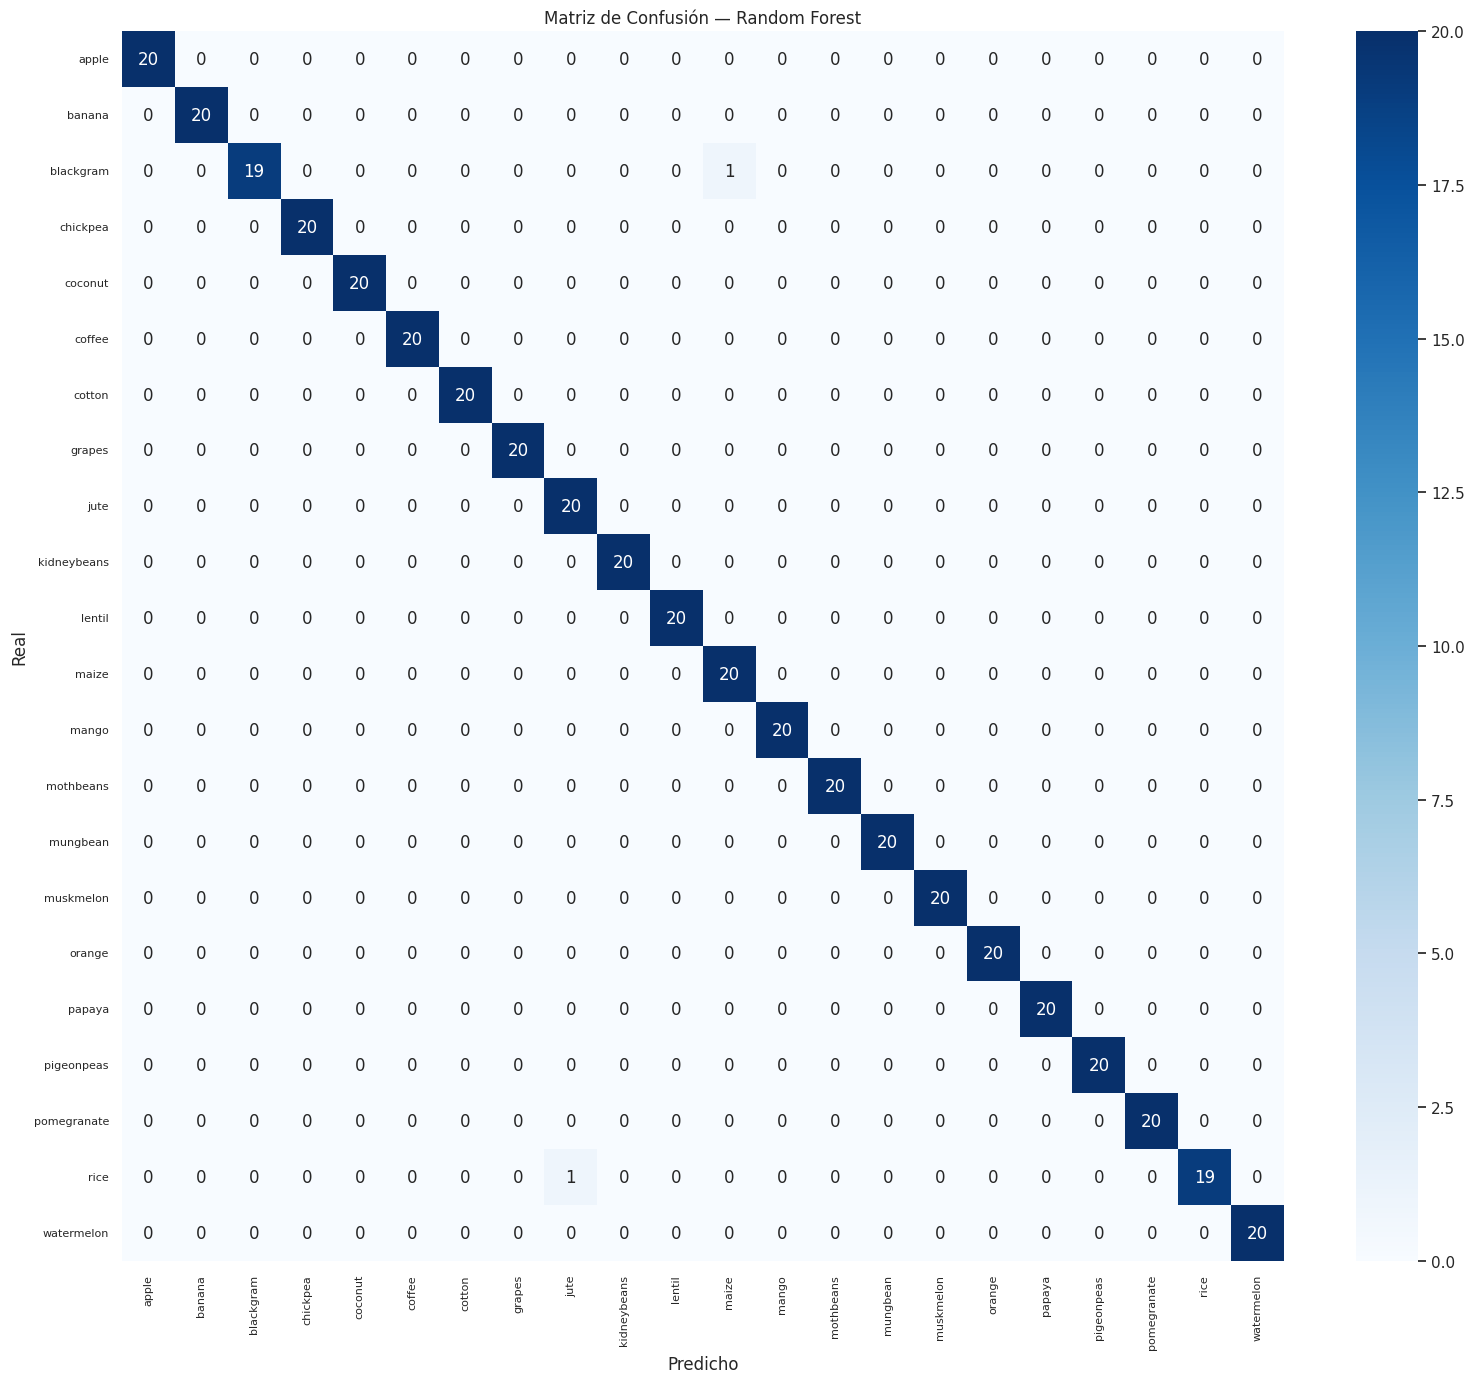

Accuracy global: 99.55%


In [15]:
# Matriz de confusión 22×22
cm = confusion_matrix(y_test, y_pred, labels=sorted(y_test.unique()))

fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=sorted(y_test.unique()),
            yticklabels=sorted(y_test.unique()), ax=ax)
ax.set_xlabel('Predicho'); ax.set_ylabel('Real')
ax.set_title(f'Matriz de Confusión — {best_name}')
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout(); plt.show()

acc = np.trace(cm) / cm.sum()
print(f'Accuracy global: {acc:.2%}')


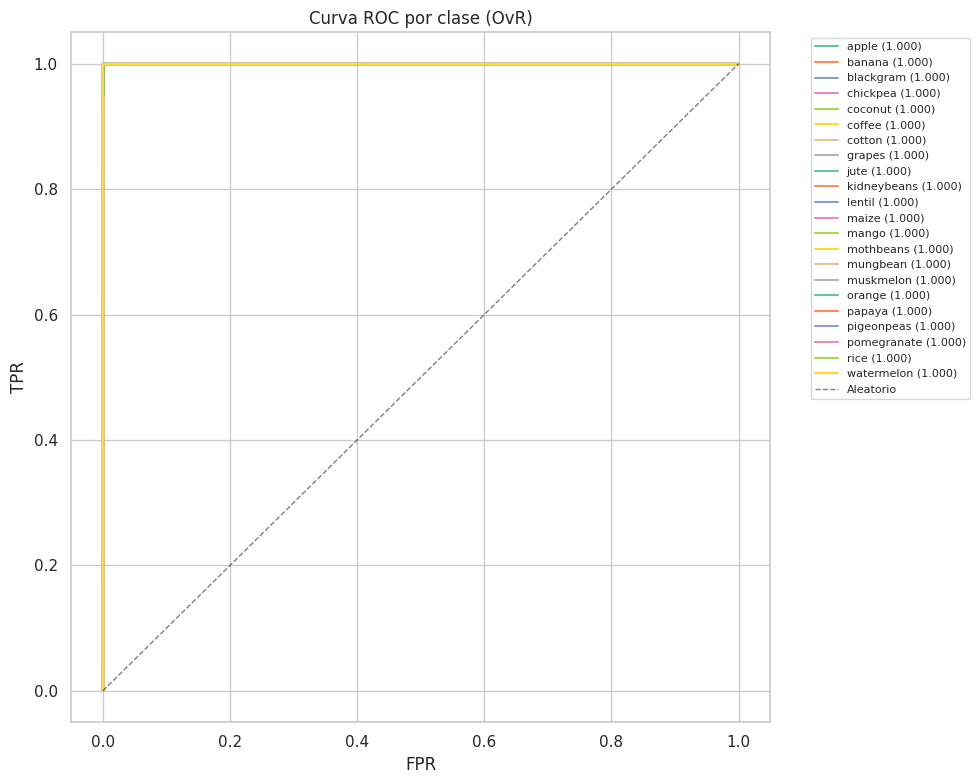

AUC macro promedio: 1.0000
Peor clase: jute (0.9999)
Mejor clase: apple (1.0000)


In [16]:
# Curva ROC por clase (One-vs-Rest)
classes = sorted(y_test.unique())

auc_per_class = roc_auc_score(y_test, best_probs, multi_class='ovr', average=None)

fig, ax = plt.subplots(figsize=(10, 8))
for i, cls in enumerate(classes):
    y_bin = (y_test == cls).astype(int)
    fpr, tpr, _ = roc_curve(y_bin, best_probs[:, i])
    ax.plot(fpr, tpr, label=f'{cls} ({auc_per_class[i]:.3f})', lw=1.5)

ax.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.5, label='Aleatorio')
ax.set(xlabel='FPR', ylabel='TPR', title='Curva ROC por clase (OvR)')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.tight_layout(); plt.show()

print(f'AUC macro promedio: {auc_per_class.mean():.4f}')
print(f'Peor clase: {classes[auc_per_class.argmin()]} ({auc_per_class.min():.4f})')
print(f'Mejor clase: {classes[auc_per_class.argmax()]} ({auc_per_class.max():.4f})')


## Análisis de Error
Perfiles sintéticos para probar el modelo manualmente y revisión de
confusiones más frecuentes entre pares de cultivos.


In [17]:
# Perfiles sintéticos de suelo/clima
synthetic = pd.DataFrame({
    'N': [20, 90, 40, 100, 15],
    'P': [60, 45, 50, 20, 80],
    'K': [30, 40, 20, 50, 15],
    'temperature': [25, 24, 30, 22, 20],
    'humidity': [80, 82, 70, 90, 85],
    'ph': [6.5, 6.8, 6.0, 7.0, 5.5],
    'rainfall': [200, 250, 100, 180, 300],
})

desc = [
    'suelo medio, clima templado, lluvia moderada',
    'nitrógeno alto, ph neutro, lluvia alta',
    'ph ácido, poca lluvia, temperatura alta',
    'nitrógeno muy alto, humedad alta, poca lluvia',
    'ph muy ácido, mucha lluvia, potasio bajo',
]

probs = best_model.predict_proba(synthetic)
preds = best_model.predict(synthetic)

for i in range(len(synthetic)):
    top3_idx = probs[i].argsort()[::-1][:3]
    top3 = [(classes[j], probs[i][j]) for j in top3_idx]
    print(f'{i+1}. {desc[i]}')
    print(f'   Predicción: {preds[i]}')
    print(f'   Top 3: {top3[0][0]} ({top3[0][1]:.1%}), {top3[1][0]} ({top3[1][1]:.1%}), {top3[2][0]} ({top3[2][1]:.1%})\n')


1. suelo medio, clima templado, lluvia moderada
   Predicción: papaya
   Top 3: papaya (24.3%), pigeonpeas (15.4%), coconut (12.4%)

2. nitrógeno alto, ph neutro, lluvia alta
   Predicción: rice
   Top 3: rice (94.4%), jute (5.6%), pomegranate (0.0%)

3. ph ácido, poca lluvia, temperatura alta
   Predicción: pigeonpeas
   Top 3: pigeonpeas (55.9%), mothbeans (22.8%), mango (9.5%)

4. nitrógeno muy alto, humedad alta, poca lluvia
   Predicción: watermelon
   Top 3: watermelon (21.0%), papaya (15.6%), rice (13.3%)

5. ph muy ácido, mucha lluvia, potasio bajo
   Predicción: pigeonpeas
   Top 3: pigeonpeas (41.6%), orange (9.3%), papaya (8.6%)



In [18]:
# Análisis de errores por clase real
results = pd.DataFrame({'real': y_test.values, 'pred': y_pred})
errors = results[results['real'] != results['pred']]

print(f'Errores totales: {len(errors)}/{len(results)} ({len(errors)/len(results):.1%})')

# Errores por clase
error_counts = errors['real'].value_counts().sort_values(ascending=False)
print(f'\nErrores por clase:')
for cls, count in error_counts.items():
    total_cls = (results['real'] == cls).sum()
    print(f'  {cls:12s}: {count:3d}/{total_cls} ({count/total_cls:.0%})')

# Pares de confusión más frecuentes
print(f'\nTop 5 confusiones:')
conf_pairs = errors.groupby(['real', 'pred']).size().sort_values(ascending=False).head(5)
for (real, pred), count in conf_pairs.items():
    print(f'  {real:12s} → {pred:12s}: {count} casos')


Errores totales: 2/440 (0.5%)

Errores por clase:
  blackgram   :   1/20 (5%)
  rice        :   1/20 (5%)

Top 5 confusiones:
  blackgram    → maize       : 1 casos
  rice         → jute        : 1 casos


## Conclusiones y Limitaciones

### Resultados
- AUC macro superior a 0.95 y accuracy sobre 90%, lo que refleja la alta separabilidad
  de las 22 clases en el espacio de features disponible.
- Random Forest y Gradient Boosting rinden de forma muy similar, con diferencias
  marginales que dependen de la semilla y la partición.

### Limitaciones
- **Dataset ideal**: balance perfecto, sin nulos, sin outliers. Es un escenario favorable.
  La diferencia con TabPFN podría ser menor que en datasets más ruidosos.
- **Features limitadas**: 7 variables. No hay datos de satélite, historial de cultivos
  ni condiciones estacionales como duración del día o temperatura mínima/máxima.
- **Confusiones entre cultivos similares**: pares como kidneybeans/mungbean se confunden
  porque sus requerimientos nutricionales son cercanos.
- **Generalización**: el modelo funciona dentro del rango de entrenamiento.
  Condiciones extremas o nuevos cultivos no están cubiertos.

### Próximo paso
Comparar estos resultados con **TabPFN** usando el mismo test set exportado.
La pregunta es si un foundation model reduce las confusiones entre clases similares.
